# E-commerce Customer Behavior Analysis

## Project Overview

This project explores customer behavior, purchasing patterns, and churn using an e-commerce customer dataset containing 50,000 customer records and 25 variables.

The analysis investigates relationships between customer engagement, purchase activity, discount usage, customer lifetime value, and retention-related indicators. The findings are summarized through exploratory data analysis and a Power BI dashboard.

## Objectives

Examine relationships between login frequency and recency of purchase.

Explore associations between social media engagement, discount usage, and purchasing behavior.

Compare returns and customer service interactions between retained and churned customers.

Investigate the relationship between total purchases and customer lifetime value.

Examine whether membership duration is associated with login frequency.

Tools and Technologies

Python

Pandas

Matplotlib

Jupyter Notebook

Power BI

## Dataset and Scope

The dataset was obtained from Kaggle: Ecommerce Customer Behavior Dataset, by dhairyajeetsingh. 

Link: https://www.kaggle.com/datasets/dhairyajeetsingh/ecommerce-customer-behavior-dataset/data

The dataset is synthetic. Therefore, the results describe patterns within this dataset and should not be interpreted as verified evidence of real-world customer behavior.

## Methodology

The project follows four stages: data inspection, data cleaning, exploratory data analysis, and dashboard development. Missing and invalid values are handled according to the needs of each analysis, and correlations are used to examine linear associations between selected variables.

## 1. Dataset Overview

### Loading Dataset into a Dataframe

In [1]:
#Importing Pandas

import pandas as pd

In [2]:
#Importing matplotlib libraray for graphs

import matplotlib.pyplot as plt

In [3]:
#Loading the csv in a dataframe

df = pd.read_csv('customer_behavior.csv')

### Inspecting the Dataset

In [4]:
#Loading the first few rows i.e 7

df.head(7)

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
5,35.0,Male,Japan,Tokyo,3.5,6.0,21.9,6.9,74.4,0.0,...,16.0,8.0,2.0,14.3,11.2,2.0,1995.43,2418.0,1,Q1
6,56.0,Male,Germany,Berlin,1.9,24.0,46.4,13.9,36.2,5.0,...,35.5,4.0,6.0,68.8,42.9,5.0,3003.57,2657.0,0,Q1


In [5]:
#Finding the exact shape of the dataset

df.shape

(50000, 25)

In [6]:
#Checking exact column names

df.columns

Index(['Age', 'Gender', 'Country', 'City', 'Membership_Years',
       'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session',
       'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases',
       'Average_Order_Value', 'Days_Since_Last_Purchase',
       'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate',
       'Customer_Service_Calls', 'Product_Reviews_Written',
       'Social_Media_Engagement_Score', 'Mobile_App_Usage',
       'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance',
       'Churned', 'Signup_Quarter'],
      dtype='str')

In [7]:
#Checking the exact datatypes of all columns

df.dtypes

Age                              float64
Gender                               str
Country                              str
City                                 str
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance                   float64
Churned                            int64
Signup_Quarter  

### Analyzing Missing Values

In [8]:
#Now looking for which columns have missing values and how many

df.isna().sum()

Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter                      0
dtype: int64

In [9]:
#Now displaying in percentage how many values does NaN values make up for each column

(df.isna().mean() * 100).map("{:.1f}%".format)

Age                               5.0%
Gender                            0.0%
Country                           0.0%
City                              0.0%
Membership_Years                  0.0%
Login_Frequency                   0.0%
Session_Duration_Avg              6.8%
Pages_Per_Session                 6.0%
Cart_Abandonment_Rate             0.0%
Wishlist_Items                    8.0%
Total_Purchases                   0.0%
Average_Order_Value               0.0%
Days_Since_Last_Purchase          6.0%
Discount_Usage_Rate               7.0%
Returns_Rate                      9.0%
Email_Open_Rate                   5.1%
Customer_Service_Calls            0.3%
Product_Reviews_Written           7.0%
Social_Media_Engagement_Score    12.0%
Mobile_App_Usage                 10.0%
Payment_Method_Diversity          5.0%
Lifetime_Value                    0.0%
Credit_Balance                   11.0%
Churned                           0.0%
Signup_Quarter                    0.0%
dtype: str

In [10]:
#Checking how many records/rows have atleast one missing value

df.isna().any(axis=1).sum()

np.int64(32017)

In [11]:
#Checking what percent or rows have atleast one missing cell

(df.isna().any(axis=1).mean() * 100)

np.float64(64.034)

### Finding if a there are any duplicate Values

In [12]:
#Analyzing if any duplicate record is present

df.duplicated().sum()

np.int64(0)

### Looking up unique values

In [13]:
#Checking unique values of categorical columns staring with Gender

df.Gender.unique()

<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

In [14]:
#Now country

df.Country.unique()

<StringArray>
['France', 'UK', 'Canada', 'USA', 'India', 'Japan', 'Germany', 'Australia']
Length: 8, dtype: str

In [15]:
#Now Churned

df.Churned.unique()

array([0, 1])

In [16]:
#And also Signup Quarter

df.Signup_Quarter.unique()

<StringArray>
['Q1', 'Q4', 'Q2', 'Q3']
Length: 4, dtype: str

### Exploring the numerical columns

In [17]:
#Now Analyzing numerical columns for stats such as Mean, Median, Standard Deviation, Max and MIn values

df.describe()

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,...,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.000000,50000.000000,50000.000000,46601.000000,47000.000000,50000.000000,46000.000000,50000.000000,50000.000000,47000.000000,...,45509.000000,47472.000000,49832.000000,46500.000000,44000.000000,45000.000000,47500.000000,50000.000000,44500.000000,50000.000000
mean,37.802968,2.984009,11.624660,27.660754,8.737811,57.079973,4.298391,13.111576,123.117330,29.792872,...,6.680913,20.937980,5.681831,2.853312,29.364466,19.371607,2.353874,1440.626292,1966.233258,0.289000
std,11.834668,2.059105,7.810657,10.871013,3.778220,16.282723,3.189754,7.017312,175.569714,29.695062,...,6.143027,14.252561,2.676052,2.328948,20.574021,9.419252,1.110012,907.249443,1225.072166,0.453302
min,5.000000,0.100000,0.000000,1.000000,1.000000,0.000000,0.000000,-13.000000,26.380000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,29.000000,1.400000,6.000000,19.700000,6.000000,46.400000,2.000000,8.000000,87.050000,9.000000,...,2.900000,9.900000,4.000000,1.000000,13.200000,12.500000,2.000000,789.817500,1049.000000,0.000000
50%,38.000000,2.500000,11.000000,26.800000,8.400000,58.100000,4.000000,12.000000,112.970000,21.000000,...,5.400000,19.700000,5.000000,2.000000,27.600000,18.600000,2.000000,1243.415000,1896.000000,0.000000
75%,46.000000,4.000000,17.000000,34.700000,11.200000,68.700000,6.000000,17.000000,144.440000,41.000000,...,9.100000,30.400000,7.000000,4.000000,43.100000,25.500000,3.000000,1874.000000,2791.000000,1.000000
max,200.000000,10.000000,46.000000,75.600000,24.100000,143.743350,28.000000,128.700000,9666.379178,287.000000,...,99.615734,91.700000,21.000000,21.000000,100.000000,61.900000,5.000000,8987.240000,7197.000000,1.000000


In [18]:
#How many age are above 100

df.loc[df['Age'] > 100].shape[0]

20

In [19]:
#How many age are below 18

df.loc[df['Age'] < 18].shape[0]

30

In [20]:
#How many Total Purchases are negative

df.loc[df['Total_Purchases'] < 0].shape[0]

40

In [21]:
#How many Total Purchases are 1000 or above

df.loc[df['Total_Purchases'] >= 100].shape[0]

13

In [22]:
#How many Total Purchases have any decimal value except .0

df.loc[df['Total_Purchases'] % 1 != 0].shape[0]

11241

In [23]:
#How much Cart abandment is greater then 100

df.loc[df['Cart_Abandonment_Rate'] > 100].shape[0]

30

In [24]:
#How many values in Discount Usage are greater then 100

df.loc[df['Discount_Usage_Rate'] > 100].shape[0]

207

In [25]:
#How many values in Average order value are 1000 or greater

df.loc[df['Average_Order_Value'] >= 1000].shape[0]

25

## 2. Cleaning and Preprocessing

### Data Cleaning Approach

The original dataset is preserved, and cleaning is performed on a separate working copy. Invalid values are handled according to the requirements of the relevant variables and analyses. Missing values are retained where appropriate, with complete-case filtering applied separately for each research question. This avoids removing entire customer records unnecessarily when a particular analysis does not require every variable.

### Exploring how many anamolies

In [26]:
#Dealing with Age

#Lets check how many customers are below age 18 and age 14

(df['Age'] < 18).sum()

np.int64(30)

In [27]:
(df['Age'] < 14).sum()

np.int64(30)

In [28]:
#Lets check how many customers are above 100

(df['Age'] > 100).sum()

np.int64(20)

In [29]:
#Lets check how many negative values are in Total Purchases

(df['Total_Purchases'] < 0).sum()

np.int64(40)

In [30]:
#Lets check how many above 100 values are in Discount Usage and Cart Abandment

print((df['Discount_Usage_Rate'] > 100).sum())

print((df['Cart_Abandonment_Rate'] > 100).sum())

207
30


### Exploring NaN values for each analytical question

In [31]:
# For NaN values, lets check how much of missing data is present for each question

#Q1: Does more frequent login tend to correspond to fewer days since the last purchase?

df.loc[df['Login_Frequency'].isna() | df['Days_Since_Last_Purchase'].isna()]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
73,56.0,Male,India,Chennai,2.6,6.0,22.9,5.9,62.8,2.0,...,29.2,7.0,4.0,45.5,6.8,3.0,619.33,2499.0,0,Q4
88,31.0,Female,USA,Chicago,1.2,32.0,37.1,14.8,46.3,5.0,...,32.6,5.0,5.0,NaN,NaN,3.0,2893.20,2134.0,0,Q2
100,21.0,Male,USA,New York,1.5,0.0,11.6,5.4,80.8,3.0,...,2.2,4.0,1.0,28.6,18.6,2.0,1212.35,1015.0,0,Q2
102,33.0,Male,USA,Los Angeles,6.6,27.0,48.5,13.5,54.8,7.0,...,30.7,3.0,6.0,14.8,23.2,1.0,2159.92,4225.0,0,Q2
124,45.0,Male,USA,Houston,2.3,28.0,45.7,15.8,23.4,11.0,...,41.8,3.0,8.0,51.5,29.9,2.0,4964.67,2231.0,0,Q4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49914,31.0,Male,USA,New York,1.3,21.0,31.8,8.1,54.0,3.0,...,16.4,3.0,2.0,47.9,18.5,3.0,993.42,3089.0,0,Q2
49927,58.0,Male,Germany,Berlin,0.5,16.0,42.8,15.7,37.8,3.0,...,36.8,5.0,3.0,51.7,29.1,2.0,1350.30,3044.0,0,Q2
49936,38.0,Male,Australia,Perth,4.9,6.0,21.5,5.1,67.9,1.0,...,4.3,5.0,0.0,NaN,11.3,3.0,584.14,512.0,0,Q4
49949,34.0,Male,Germany,Hamburg,4.4,21.0,53.1,12.7,32.6,NaN,...,33.3,0.0,9.0,81.1,32.9,2.0,1849.40,2525.0,1,Q3


In [32]:
#Q2: Is social-media engagement associated with total purchases?

df.loc[df['Social_Media_Engagement_Score'].isna() | df['Total_Purchases'].isna()]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
13,18.0,Female,USA,Phoenix,3.1,13.0,26.1,8.9,47.7,2.0,...,19.0,8.0,4.0,NaN,21.5,3.0,1083.91,2772.0,1,Q3
31,60.0,Female,Germany,Hamburg,4.9,27.0,45.6,NaN,35.1,NaN,...,57.8,3.0,6.0,NaN,42.7,3.0,1633.16,NaN,0,Q2
38,22.0,Male,USA,Los Angeles,0.7,13.0,35.0,11.4,47.7,7.0,...,26.0,4.0,5.0,NaN,29.3,5.0,1671.72,2021.0,1,Q4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49956,36.0,Female,Germany,Frankfurt,0.7,10.0,24.4,8.7,65.8,3.0,...,9.4,5.0,1.0,NaN,13.0,1.0,1234.32,1297.0,0,Q2
49958,35.0,Female,Australia,Sydney,1.5,11.0,16.0,4.6,66.2,3.0,...,8.7,6.0,2.0,NaN,5.5,2.0,885.66,1141.0,0,Q2
49962,51.0,Other,USA,Phoenix,0.8,3.0,21.0,6.8,83.5,0.0,...,0.0,5.0,1.0,NaN,5.2,5.0,780.36,NaN,1,Q3
49989,44.0,Female,France,Toulouse,4.5,5.0,22.4,9.5,49.6,9.0,...,21.3,7.0,3.0,NaN,29.0,1.0,601.74,2201.0,0,Q2


In [33]:
#Q3: Is discount usage associated with purchasing behavior?

df.loc[df['Discount_Usage_Rate'].isna() | df['Total_Purchases'].isna()]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
17,41.0,Male,USA,Los Angeles,0.7,5.0,19.5,5.3,68.0,2.0,...,1.2,4.0,NaN,0.0,13.4,1.0,1356.93,1924.0,0,Q4
19,21.0,Female,Australia,Adelaide,5.6,9.0,27.5,8.8,52.1,4.0,...,NaN,7.0,5.0,28.2,25.6,1.0,1274.70,3107.0,0,Q3
35,23.0,Male,UK,Glasgow,2.1,4.0,38.7,7.7,47.0,8.0,...,22.3,8.0,6.0,36.7,24.1,1.0,1024.65,2564.0,0,Q2
50,41.0,Male,UK,Leeds,1.7,18.0,36.5,NaN,44.9,3.0,...,18.9,3.0,5.0,38.6,36.1,2.0,870.26,2737.0,0,Q4
55,49.0,Female,USA,Houston,1.8,0.0,13.2,5.8,58.6,1.0,...,11.9,9.0,2.0,0.9,6.6,4.0,2134.96,0.0,1,Q1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49946,23.0,Male,UK,London,7.4,9.0,16.7,3.8,74.3,1.0,...,17.6,5.0,NaN,NaN,16.2,1.0,295.39,100.0,0,Q3
49950,18.0,Male,Japan,Tokyo,1.2,5.0,9.5,1.0,69.1,1.0,...,4.5,6.0,0.0,25.3,6.0,3.0,743.16,0.0,0,Q3
49970,45.0,Male,UK,London,1.8,25.0,54.0,9.1,35.9,4.0,...,39.6,6.0,5.0,62.3,29.4,3.0,1926.58,1880.0,1,Q1
49972,38.0,Male,India,Delhi,2.0,26.0,51.5,13.9,8.4,10.0,...,40.0,0.0,8.0,36.5,NaN,3.0,2500.87,4142.0,0,Q2


In [34]:
#Q4: Do churned customers have higher return rates and customer service calls than retained customers?

#As Churned has no NaN value,we can check the otehr 2
df.loc[df['Returns_Rate'].isna() | df['Customer_Service_Calls'].isna()]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
9,44.0,Male,USA,New York,3.6,13.0,31.3,5.4,62.6,3.0,...,11.7,2.0,1.0,13.5,21.5,2.0,807.84,977.0,0,Q2
30,30.0,Male,Germany,Cologne,5.4,8.0,27.0,9.0,61.0,3.0,...,4.6,9.0,5.0,15.4,NaN,3.0,1585.98,240.0,0,Q1
37,18.0,Male,France,Marseille,0.9,22.0,39.4,13.3,39.1,10.0,...,30.9,4.0,9.0,23.9,31.8,2.0,1869.92,2882.0,0,Q1
61,35.0,Male,USA,Phoenix,1.7,5.0,20.8,6.9,70.2,3.0,...,22.0,7.0,3.0,47.2,12.8,2.0,1125.37,21.0,0,Q3
64,47.0,Female,USA,Phoenix,4.8,16.0,45.7,12.7,41.7,7.0,...,48.3,3.0,4.0,29.8,32.9,2.0,1717.65,4181.0,0,Q3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49929,41.0,Male,Australia,Melbourne,0.1,11.0,39.8,7.3,66.8,5.0,...,26.7,9.0,1.0,10.8,19.5,1.0,1364.76,3644.0,0,Q3
49962,51.0,Other,USA,Phoenix,0.8,3.0,21.0,6.8,83.5,0.0,...,0.0,5.0,1.0,NaN,5.2,5.0,780.36,NaN,1,Q3
49969,63.0,Male,Australia,Perth,3.1,19.0,49.8,9.6,37.5,8.0,...,42.2,5.0,4.0,40.2,26.7,2.0,2609.23,3109.0,0,Q1
49995,38.0,Female,USA,Los Angeles,10.0,10.0,35.8,8.8,51.2,3.0,...,9.2,5.0,1.0,20.7,25.2,1.0,2365.98,3499.0,0,Q2


In [35]:
#Q5: Is a higher number of total purchases associated with higher customer lifetime value??

df.loc[df['Total_Purchases'].isna() | df['Lifetime_Value'].isna()]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter


In [36]:
#Q6: Do customers with longer membership durations tend to have higher login frequency?

df.loc[df['Membership_Years'].isna() | df['Login_Frequency'].isna()]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter


### Handling Anamolies

In [37]:
#Handling Anamolies

#Ages below 14 and above 100
#Replace them with 0

df.loc[(df['Age'] < 14) | (df['Age'] > 100), 'Age'] = 0

In [38]:
#Checking if any record now has age less then 14 and above 100

df.loc[(df['Age'] < 14) | (df['Age'] > 100)]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
709,0.0,Female,USA,Los Angeles,0.6,12.0,34.5,9.0,36.4,3.0,...,8.6,6.0,5.0,25.3,16.5,1.0,1236.79,NaN,1,Q2
1745,0.0,Female,USA,Los Angeles,10.0,4.0,24.8,4.9,71.1,NaN,...,0.0,6.0,1.0,6.4,16.0,1.0,612.94,799.0,1,Q1
2616,0.0,Male,USA,Los Angeles,2.0,5.0,24.2,NaN,75.9,3.0,...,3.2,8.0,2.0,0.0,13.9,4.0,1182.22,3824.0,1,Q1
6715,0.0,Male,Australia,Adelaide,5.7,24.0,50.1,11.3,27.3,10.0,...,48.7,1.0,6.0,88.2,38.6,2.0,3323.73,4076.0,0,Q2
7019,0.0,Female,USA,Chicago,2.1,19.0,40.8,8.8,49.1,4.0,...,26.7,5.0,5.0,46.3,31.5,2.0,1778.25,NaN,0,Q4
7315,0.0,Female,Germany,Hamburg,0.6,1.0,NaN,7.0,79.1,0.0,...,0.0,8.0,1.0,29.0,9.7,2.0,981.94,0.0,1,Q2
7817,0.0,Male,France,Lyon,1.9,10.0,20.8,7.5,60.2,2.0,...,18.7,6.0,2.0,0.0,NaN,1.0,1698.67,1802.0,1,Q1
8809,0.0,Female,USA,New York,2.1,9.0,27.6,3.1,57.5,1.0,...,3.5,6.0,1.0,36.0,11.3,4.0,662.87,1170.0,0,Q2
9391,0.0,Female,UK,Glasgow,3.4,22.0,47.7,12.3,37.8,11.0,...,28.4,2.0,6.0,50.2,29.7,4.0,2651.14,4335.0,1,Q4
10985,0.0,Female,USA,Chicago,2.3,5.0,30.7,7.8,45.8,2.0,...,19.2,11.0,1.0,NaN,9.4,3.0,985.88,1076.0,1,Q2


In [39]:
#Now Handling Discount Usage rate over 100

#We will replace them with NaN

df.loc[(df['Discount_Usage_Rate'] > 100), 'Discount_Usage_Rate'] = pd.NA

In [40]:
#Checking if any record now has Discount usage rate over 100

df.loc[(df['Discount_Usage_Rate'] > 100) ]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter


In [41]:
#Now Handling Cart_Abandonment_Rate  over 100

#We will replace them with NaN

df.loc[(df['Cart_Abandonment_Rate'] > 100), 'Cart_Abandonment_Rate'] = pd.NA

In [42]:
#Checking if any record now has Cart_Abandonment_Rate over 100

df.loc[(df['Cart_Abandonment_Rate'] > 100) ]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter


In [43]:
#Now Handling Total Purchases, which have negative value

#We will replace them with NaN

df.loc[(df['Total_Purchases'] < 0), 'Total_Purchases'] = pd.NA

In [44]:
#Checking if any record now has Total_Purchases has negative value left

df.loc[(df['Total_Purchases'] < 0) ]

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter


In [45]:
#Now Handling Total Purchases, which have any decimal value

#We will replace roung them off, but keep .0 as we are not changing the datatype of the column

df['Total_Purchases'] = df['Total_Purchases'].round(0)

In [46]:
#Now lets check

df.loc[df['Total_Purchases'] % 1 != 0]['Total_Purchases'].shape[0]

40

In [47]:
df.loc[df['Total_Purchases'] % 1 == 0]['Total_Purchases']

0         9.0
1        20.0
2         9.0
3        15.0
4        32.0
         ... 
49995    13.0
49996    15.0
49997    12.0
49998    12.0
49999     9.0
Name: Total_Purchases, Length: 49960, dtype: float64

In [48]:
df.isna().sum()

Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate              30
Wishlist_Items                   4000
Total_Purchases                    40
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3707
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter                      0
dtype: int64

In [49]:
#Now saving this dataframe as a cleaned csv
#We can later use this for Power BI Dashboard development

df.to_csv('cleaned_dataset.csv', index=False)

## Data Analysis and Trends

### We will perfrom analysis and identify trends for each question

### Q1: Does more frequent login tend to correspond to fewer days since the last purchase?

In [50]:
# We will focus our analysis on the attributes Login_Frequency and Days_Since_Last_Purchase
# As we know we have 3000 records with NaN values in anyone of them

# Filtering those rows out

temp = df.loc[(df['Days_Since_Last_Purchase'].notna()) & (df['Login_Frequency'].notna())]

temp

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,38.0,Female,USA,Los Angeles,10.0,10.0,35.8,8.8,51.2,3.0,...,9.2,5.0,1.0,20.7,25.2,1.0,2365.98,3499.0,0,Q2
49996,37.0,Male,USA,Chicago,1.4,21.0,32.4,9.6,32.5,2.0,...,17.6,5.0,3.0,38.6,12.1,4.0,1293.60,3154.0,0,Q3
49997,44.0,Female,USA,Phoenix,2.8,19.0,40.3,10.4,50.6,1.0,...,25.2,4.0,6.0,59.9,NaN,1.0,1655.28,1622.0,0,Q1
49998,41.0,Female,USA,Chicago,2.9,17.0,29.9,10.1,60.8,1.0,...,34.6,5.0,2.0,NaN,14.1,3.0,1286.11,2634.0,0,Q2


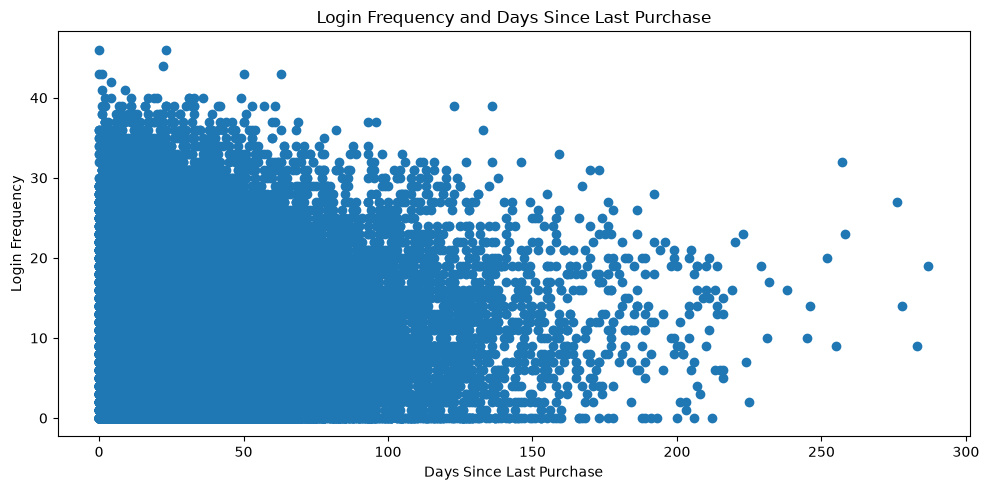

In [51]:
#Generating a Scatter Plot
#Scatter Plot to visualize Login Frequency and Days Since Last Purchase

plt.figure(figsize=(10,5))

#Labeling The Graph
plt.title('Login Frequency and Days Since Last Purchase')
plt.xlabel('Days Since Last Purchase')
plt.ylabel('Login Frequency')

#Ploting The Grapgh
plt.scatter(temp['Days_Since_Last_Purchase'], temp['Login_Frequency'])

plt.tight_layout()

plt.savefig('images/login_frequency_vs_days_since_last_purchase.png') #Saving Grapgh as Image

plt.show()

In [52]:
# Calculating corealeation to further support our hypothesis

#Finding correlations

coreleation = temp['Days_Since_Last_Purchase'].corr(temp['Login_Frequency'])
print('Coreleation between Days_Since_Last_Purchase and Login_Frequency: {}'.format(coreleation))

Coreleation between Days_Since_Last_Purchase and Login_Frequency: 0.0036367692034417333


### Q2: Is social-media engagement associated with total purchases?

In [53]:
# We will focus our analysis on the attributes Social_Media_Engagement_Score and Total_Purchases
# As we know we have 6000 records with NaN values in anyone of them

# Filtering those rows out

temp = df.loc[(df['Total_Purchases'].notna()) & (df['Social_Media_Engagement_Score'].notna())]

temp

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
5,35.0,Male,Japan,Tokyo,3.5,6.0,21.9,6.9,74.4,0.0,...,16.0,8.0,2.0,14.3,11.2,2.0,1995.43,2418.0,1,Q1
6,56.0,Male,Germany,Berlin,1.9,24.0,46.4,13.9,36.2,5.0,...,35.5,4.0,6.0,68.8,42.9,5.0,3003.57,2657.0,0,Q1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49994,18.0,Female,France,Lyon,4.8,8.0,21.0,8.4,69.5,3.0,...,17.4,6.0,5.0,15.4,14.6,2.0,813.11,3565.0,1,Q2
49995,38.0,Female,USA,Los Angeles,10.0,10.0,35.8,8.8,51.2,3.0,...,9.2,5.0,1.0,20.7,25.2,1.0,2365.98,3499.0,0,Q2
49996,37.0,Male,USA,Chicago,1.4,21.0,32.4,9.6,32.5,2.0,...,17.6,5.0,3.0,38.6,12.1,4.0,1293.60,3154.0,0,Q3
49997,44.0,Female,USA,Phoenix,2.8,19.0,40.3,10.4,50.6,1.0,...,25.2,4.0,6.0,59.9,NaN,1.0,1655.28,1622.0,0,Q1


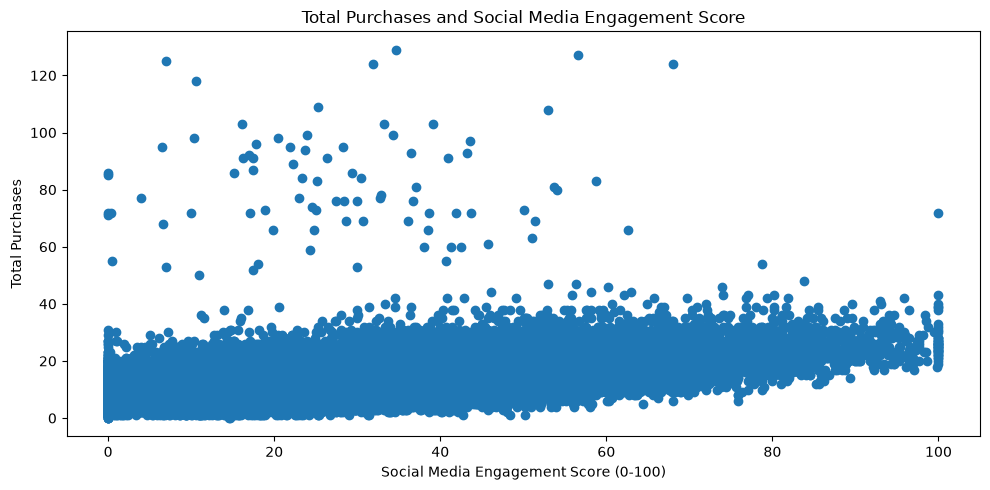

In [54]:
#Generating a Scatter Plot
#Scatter Plot to visualize Total Purchases and Social Media Engagement Score

plt.figure(figsize=(10,5))

#Labeling The Graph
plt.title('Total Purchases and Social Media Engagement Score')
plt.xlabel('Social Media Engagement Score (0-100)')
plt.ylabel('Total Purchases')

#Ploting The Grapgh
plt.scatter(temp['Social_Media_Engagement_Score'], temp['Total_Purchases'])

plt.tight_layout()

plt.savefig('images/total_purchases_vs_social_media_score.png') #Saving Grapgh as Image

plt.show()

In [55]:
# Calculating corealeation to further support our hypothesis

#Finding correlations

coreleation = temp['Total_Purchases'].corr(temp['Social_Media_Engagement_Score'])
print('Coreleation between Total_Purchases and Social_Media_Engagement_Score: {}'.format(coreleation))

Coreleation between Total_Purchases and Social_Media_Engagement_Score: 0.5469381431047399


### Q3: Is discount usage associated with purchasing behavior?

In [56]:
# We will focus our analysis on the attributes Discount_Usage_Rate and Total_Purchases
# As we know we have 3500 records with NaN values in anyone of them

# Filtering those rows out

temp = df.loc[(df['Total_Purchases'].notna()) & (df['Discount_Usage_Rate'].notna())]

temp

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49994,18.0,Female,France,Lyon,4.8,8.0,21.0,8.4,69.5,3.0,...,17.4,6.0,5.0,15.4,14.6,2.0,813.11,3565.0,1,Q2
49995,38.0,Female,USA,Los Angeles,10.0,10.0,35.8,8.8,51.2,3.0,...,9.2,5.0,1.0,20.7,25.2,1.0,2365.98,3499.0,0,Q2
49996,37.0,Male,USA,Chicago,1.4,21.0,32.4,9.6,32.5,2.0,...,17.6,5.0,3.0,38.6,12.1,4.0,1293.60,3154.0,0,Q3
49998,41.0,Female,USA,Chicago,2.9,17.0,29.9,10.1,60.8,1.0,...,34.6,5.0,2.0,NaN,14.1,3.0,1286.11,2634.0,0,Q2


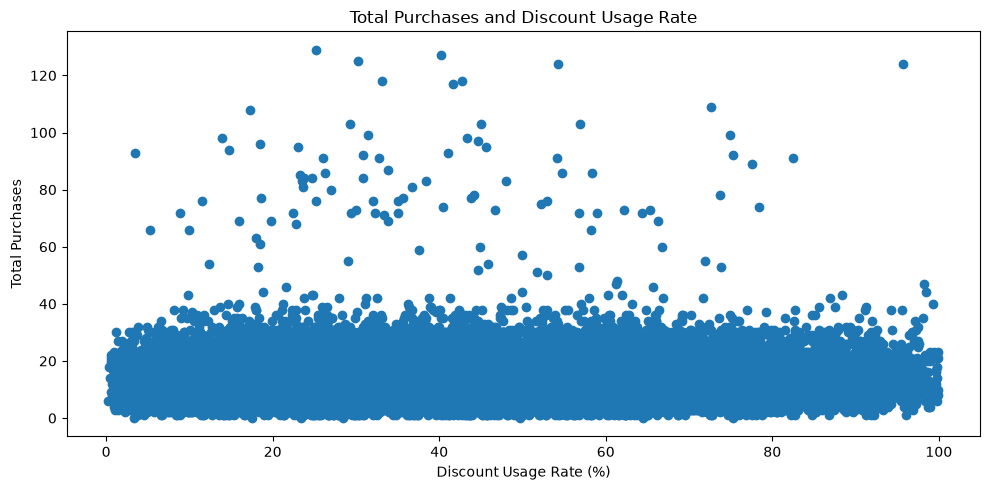

In [57]:
#Generating a Scatter Plot
#Scatter Plot to visualize Total Purchases and Discount Usage

plt.figure(figsize=(10,5))

#Labeling The Graph
plt.title('Total Purchases and Discount Usage Rate')
plt.xlabel('Discount Usage Rate (%)')
plt.ylabel('Total Purchases')

#Ploting The Grapgh
plt.scatter(temp['Discount_Usage_Rate'], temp['Total_Purchases'])

plt.tight_layout()

plt.savefig('images/total_purchases_vs_discount_usage_rate.png') #Saving Grapgh as Image

plt.show()

In [58]:
# Calculating corealeation to further support our hypothesis

#Finding correlations

coreleation = temp['Total_Purchases'].corr(temp['Discount_Usage_Rate'])
print('Coreleation between Total_Purchases and Discount_Usage_Rate: {}'.format(coreleation))

Coreleation between Total_Purchases and Discount_Usage_Rate: 0.03210982344461202


### Q4: Do churned customers have higher return rates and customer service calls than retained customers?

In [59]:
# We will focus our analysis on the attributes Returns_Rate, Customer_Service_Calls  and Churned
# As we know we have above 4000 records with NaN values in anyone of them

# Filtering those rows out

temp = df.loc[(df['Churned'].notna()) & (df['Returns_Rate'].notna()) & (df['Customer_Service_Calls'].notna())]

temp

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49993,56.0,Female,Canada,Calgary,2.0,14.0,35.5,8.9,52.9,12.0,...,40.5,5.0,2.0,35.4,18.3,3.0,1581.65,2732.0,0,Q3
49994,18.0,Female,France,Lyon,4.8,8.0,21.0,8.4,69.5,3.0,...,17.4,6.0,5.0,15.4,14.6,2.0,813.11,3565.0,1,Q2
49997,44.0,Female,USA,Phoenix,2.8,19.0,40.3,10.4,50.6,1.0,...,25.2,4.0,6.0,59.9,NaN,1.0,1655.28,1622.0,0,Q1
49998,41.0,Female,USA,Chicago,2.9,17.0,29.9,10.1,60.8,1.0,...,34.6,5.0,2.0,NaN,14.1,3.0,1286.11,2634.0,0,Q2


In [60]:
# Grouping Customer Records in Churned and Reatained categories

temp = temp.groupby('Churned').agg({'Returns_Rate': 'mean', 'Customer_Service_Calls': 'mean'})

temp

,Returns_Rate,Customer_Service_Calls
Churned,,
0,6.469511,5.181334
1,7.202053,6.905470


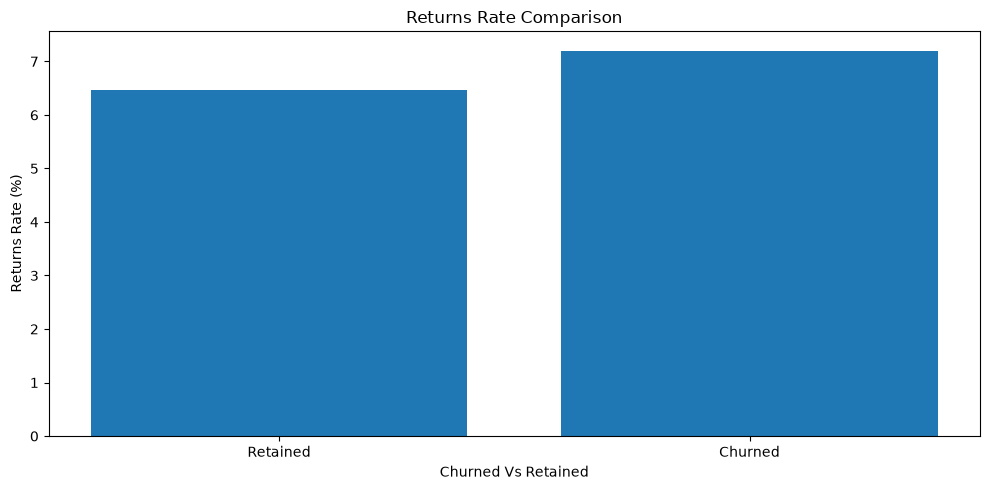

In [61]:
#Generating a Bar Graph for Returns Rate
#Bar Graph to visualize difference between Churned and Retained Customers

plt.figure(figsize=(10, 5))

#Labeling The Graph
plt.title('Returns Rate Comparison')
plt.xlabel('Churned Vs Retained')
plt.ylabel('Returns Rate (%)')

#Ploting The Grapgh
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.bar(temp.index, temp['Returns_Rate'])

plt.tight_layout()

plt.savefig('images/returns_rate_of_churnedvsretained.png') #Saving Grapgh as Image

plt.show()

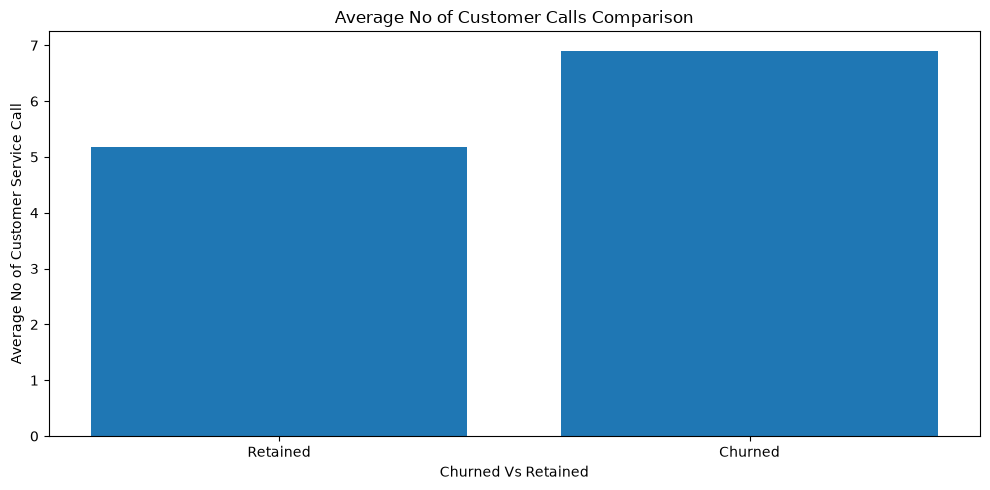

In [62]:
#Generating a Bar Graph for No of Customer Service Calls
#Bar Graph to visualize difference between Churned and Retained Customers

plt.figure(figsize=(10, 5))

#Labeling The Graph
plt.title('Average No of Customer Calls Comparison')
plt.xlabel('Churned Vs Retained')
plt.ylabel('Average No of Customer Service Call')

#Ploting The Grapgh
plt.xticks([0, 1], ['Retained', 'Churned'])
plt.bar(temp.index, temp['Customer_Service_Calls'])

plt.tight_layout()

plt.savefig('images/customer_service_calls_of_churnedvsretained.png') #Saving Grapgh as Image

plt.show()

### Q5: Is a higher number of total purchases associated with higher customer lifetime value?

In [63]:
# We will focus our analysis on the attributes Lifetime_Value and Total_Purchases
# As we know we have records with missing values for this analysis

# Filtering those rows out

temp = df.loc[(df['Total_Purchases'].notna()) & (df['Lifetime_Value'].notna())]

temp

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,38.0,Female,USA,Los Angeles,10.0,10.0,35.8,8.8,51.2,3.0,...,9.2,5.0,1.0,20.7,25.2,1.0,2365.98,3499.0,0,Q2
49996,37.0,Male,USA,Chicago,1.4,21.0,32.4,9.6,32.5,2.0,...,17.6,5.0,3.0,38.6,12.1,4.0,1293.60,3154.0,0,Q3
49997,44.0,Female,USA,Phoenix,2.8,19.0,40.3,10.4,50.6,1.0,...,25.2,4.0,6.0,59.9,NaN,1.0,1655.28,1622.0,0,Q1
49998,41.0,Female,USA,Chicago,2.9,17.0,29.9,10.1,60.8,1.0,...,34.6,5.0,2.0,NaN,14.1,3.0,1286.11,2634.0,0,Q2


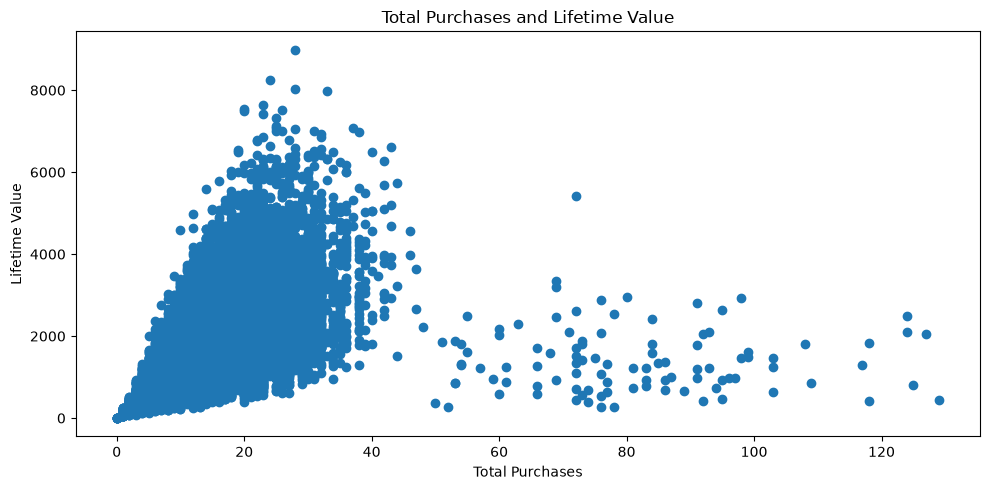

In [64]:
#Generating a Scatter Plot
#Scatter Plot to visualize Total Purchases and Lifetime Value

plt.figure(figsize=(10,5))

#Labeling The Graph
plt.title('Total Purchases and Lifetime Value')
plt.ylabel('Lifetime Value')
plt.xlabel('Total Purchases')

#Ploting The Grapgh
plt.scatter(temp['Total_Purchases'], temp['Lifetime_Value'])

plt.tight_layout()

plt.savefig('images/total_purchases_vs_lifetime_value.png') #Saving Grapgh as Image

plt.show()

In [65]:
# Calculating corealeation to further support our hypothesis

#Finding correlations

coreleation = temp['Total_Purchases'].corr(temp['Lifetime_Value'])
print('Coreleation between Total_Purchases and Lifetime_Value: {}'.format(coreleation))

Coreleation between Total_Purchases and Lifetime_Value: 0.6259534634217121


### Q6 Do customers with longer membership durations tend to have higher login frequency?

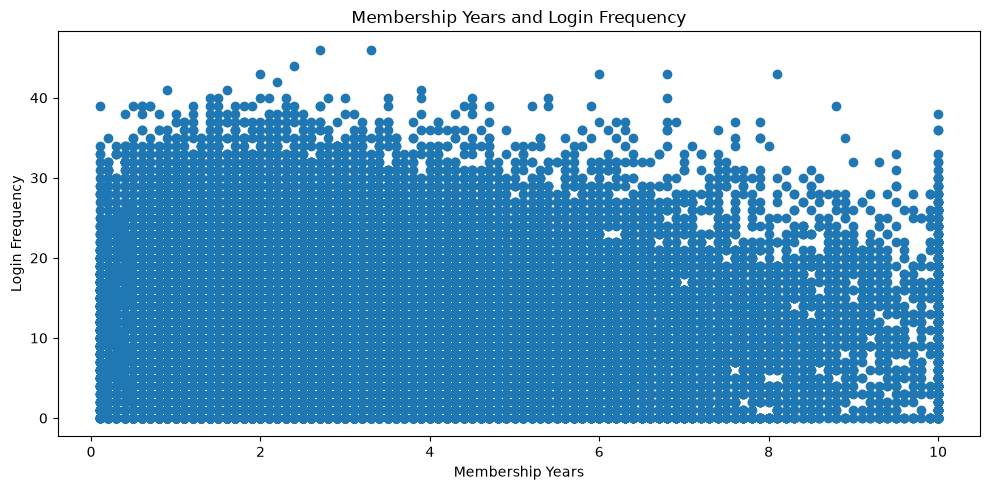

In [66]:
# We will focus our analysis on the attributes Membership_Years and Login_Frequency
# As we know we no records with missing values for this analysis

#Generating a Scatter Plot
#Scatter Plot to visualize Membership Years and Login Frequency

plt.figure(figsize=(10,5))

#Labeling The Graph
plt.title('Membership Years and Login Frequency')
plt.ylabel('Login Frequency')
plt.xlabel('Membership Years')

#Ploting The Grapgh
plt.scatter(df['Membership_Years'], df['Login_Frequency'])

plt.tight_layout()

plt.savefig('images/membership_years_vs_login_frequency.png') #Saving Grapgh as Image

plt.show()

In [67]:
# Calculating corealeation to further support our hypothesis

#Finding correlations

coreleation = df['Membership_Years'].corr(df['Login_Frequency'])
print('Coreleation between Membership_Years and Login_Frequency: {}'.format(coreleation))

Coreleation between Membership_Years and Login_Frequency: 0.0023048593039198643


## Key Findings

The analysis produced the following findings within the supplied dataset:

Login frequency and purchase recency: The correlation was approximately 0.0036, showing a negligible linear relationship.

Social media engagement and purchases: The correlation was approximately 0.5469, indicating a moderate positive linear association.

Discount usage and purchases: The correlation was approximately 0.0321, indicating a negligible linear relationship.

Customer churn: Group comparisons of average returns rates and customer service calls help describe differences between retained and churned customers. The exact differences should be reported using the calculated group means.

Purchases and lifetime value: The correlation was approximately 0.6260, indicating a moderate-to-strong positive linear association.

Membership duration and login frequency: The correlation was approximately 0.0023, indicating a negligible linear relationship.

Overall, the clearest positive associations in the selected analyses were between social media engagement and total purchases, and between total purchases and customer lifetime value. The findings are descriptive and apply only to this dataset; they should not be interpreted as evidence of causation or generalized to all e-commerce customers.

## Conclusion

### Limitations

- **Synthetic dataset:** The data is synthetic, so observed patterns may not reflect actual customer behavior in a commercial environment.
- **Missing values:** Some variables contain substantial missing data. Different analyses therefore use different sample sizes.
- **Correlation is not causation:** Correlation measures linear association and does not establish cause and effect.
- **Limited scope:** The analysis focuses on six selected relationships and does not account for every factor that could influence purchasing behavior or churn.
- **Potential data-quality issues:** Implausible ages, invalid rates, negative purchase counts and fractional purchase counts required explicit cleaning decisions. These decisions influence the resulting analysis and should be considered when interpreting findings.

### Conclusion

This project demonstrates a complete exploratory data analysis workflow, from initial data inspection and cleaning to visualization, correlation analysis and dashboard development.

The analysis identifies positive associations between social media engagement and purchase counts, and between purchase counts and customer lifetime value. Other selected relationships show negligible linear associations. Comparisons between retained and churned customers provide additional descriptive insight into returns and customer service interactions.

The accompanying Power BI dashboard presents selected findings in a business-oriented format. Further validation with real customer data would be required before using these findings to guide operational or marketing decisions.